## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

In [3]:
import pandas as pd
import sqlite3 as sql
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
conn = sql.connect('chinook.db')
conn

In [5]:
def sql_query(q):
    return pd.read_sql_query(q,conn)

In [40]:
q= """select g.name genre_name,count(t.track_id )track_count
    from genre g inner join track t
    on
    g.genre_id = t.genre_id
    group by g.name
    order by track_count desc
    limit 10
    """
sql_query(q)

,genre_name,track_count
0,Rock,1297
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61


## Q2. Write a query to list the top 10 albums that contain the most tracks.

In [7]:
q="""select al.title album_title, count(t.track_id) total_tracks
    from track t inner join album al
    on
    t.album_id=al.album_id
    group by 1
    order by 2 desc
    limit 10
"""
sql_query(q)

,album_title,total_tracks
0,Greatest Hits,57
1,Minha Historia,34
2,Unplugged,30
3,"Lost, Season 3",26
4,"The Office, Season 3",25
5,"Lost, Season 1",25
6,My Way: The Best Of Frank Sinatra [Disc 1],24
7,"Lost, Season 2",24
8,"Battlestar Galactica (Classic), Season 1",24
9,Instant Karma: The Amnesty International Campa...,23


## Q3. Write a query to find the top 10 customers who spent the most money.

In [8]:
q=""" select c.customer_id,c.first_name||" "||last_name customer_name,inv.total total_spent
from customer c inner join invoice inv
on
c.customer_id = inv.customer_id
order by 3 desc
limit 10
"""
sql_query(q)

,customer_id,customer_name,total_spent
0,42,Wyatt Girard,23.76
1,3,François Tremblay,19.80
2,32,Aaron Mitchell,19.80
3,29,Robert Brown,19.80
4,5,František Wichterlová,19.80
5,22,Heather Leacock,18.81
6,26,Richard Cunningham,17.82
7,55,Mark Taylor,17.82
8,45,Ladislav Kovács,17.82
9,39,Camille Bernard,17.82


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [14]:
q=""" select ar.name artist_name, inv.total Revenue from invoice inv
    inner join invoice_line il
    on
    inv.invoice_id=il.invoice_id
    inner join track t
    on
    il.track_id = t.track_id
    inner join album al
    on
    t.album_id = al.album_id
    inner join artist ar
    on
    al.artist_id = ar.artist_id
    group by 1
    order by 2 desc
    limit 5
"""
sql_query(q)

,artist_name,Revenue
0,Nirvana,16.83
1,Guns N' Roses,15.84
2,Yehudi Menuhin,10.89
3,Van Halen,10.89
4,U2,10.89


## Q5. Countries by Average Revenue per Invoice

In [18]:
q=""" select billing_country , round(avg(total)) Average 
    from invoice 
    group by 1
    order by 2 desc
"""
sql_query(q)

,billing_country,Average
0,United Kingdom,9.0
1,Spain,9.0
2,Ireland,9.0
3,India,9.0
4,Czech Republic,9.0
5,Belgium,9.0
6,USA,8.0
7,Sweden,8.0
8,Poland,8.0
9,Norway,8.0


## Q7. Which artists have released tracks in more than one genre?

In [20]:
q=""" select a.name Artist_name , count(distinct t.genre_id) Total_genre 
    from artist a
    inner join album al
    on
    a.artist_id = al.artist_id
    inner join track t 
    on 
    al.album_id = t.album_id
    group by 1
    having count(distinct t.genre_id) > 1
    order by 2 desc
"""
sql_query(q)

,Artist_name,Total_genre
0,Iron Maiden,4
1,Various Artists,3
2,Lenny Kravitz,3
3,Jamiroquai,3
4,Gilberto Gil,3
5,Battlestar Galactica,3
6,Audioslave,3
7,U2,2
8,The Office,2
9,Red Hot Chili Peppers,2


## Q6. Write a query to find the media type with number of tracks.


In [26]:
q=""" select mt.media_type_id , mt.name media_type_name , il.track_id Total_tracks

    from invoice_line il
    inner join track t
    on
    il.track_id=t.track_id
    inner join media_type mt
    on
    t.media_type_id =  mt.media_type_id
    group by 3 
    order by 3 desc
    limit 10
"""
sql_query(q)

,media_type_id,media_type_name,Total_tracks
0,2,Protected AAC audio file,3500
1,2,Protected AAC audio file,3495
2,2,Protected AAC audio file,3491
3,2,Protected AAC audio file,3484
4,4,Purchased AAC audio file,3480
5,2,Protected AAC audio file,3478
6,2,Protected AAC audio file,3477
7,2,Protected AAC audio file,3476
8,2,Protected AAC audio file,3475
9,2,Protected AAC audio file,3474


## Q8. Write a query to list the top 10 longest tracks by duration.

In [17]:
q=""" select  track_id , name track_name, milliseconds from track 
        group by 2
        order by 3 desc
        limit 10
        
"""
sql_query(q)

,track_id,track_name,milliseconds
0,2820,Occupation / Precipice,5286953
1,3224,Through a Looking Glass,5088838
2,3244,"Greetings from Earth, Pt. 1",2960293
3,3242,The Man With Nine Lives,2956998
4,3227,"Battlestar Galactica, Pt. 2",2956081
5,3226,"Battlestar Galactica, Pt. 1",2952702
6,3243,Murder On the Rising Star,2935894
7,3228,"Battlestar Galactica, Pt. 3",2927802
8,3248,Take the Celestra,2927677
9,3239,Fire In Space,2926593


## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

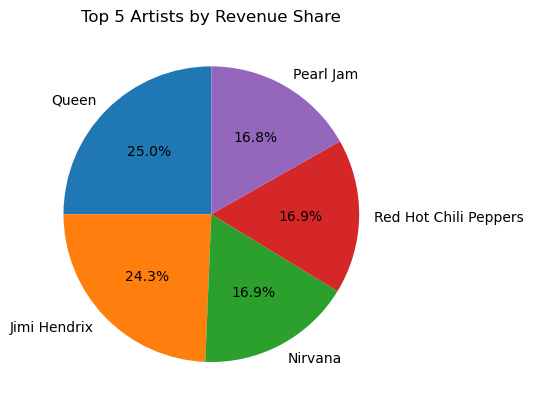

In [30]:
q="""WITH artist_revenue AS (
    SELECT
        ar.artist_id,
        ar.name AS artist,
        SUM(il.unit_price * il.quantity) AS revenue
    FROM invoice_line il
    JOIN track  t  ON t.track_id  = il.track_id
    JOIN album  al ON al.album_id = t.album_id
    JOIN artist ar ON ar.artist_id = al.artist_id
    GROUP BY ar.artist_id, ar.name
)
SELECT
    artist,
    ROUND(revenue, 2) AS revenue,
    ROUND(100.0 * revenue / SUM(revenue) OVER (), 2) AS revenue_share_pct
FROM artist_revenue
ORDER BY revenue DESC
LIMIT 5;
"""
df=sql_query(q)
plt.pie(df["revenue"], labels=df["artist"], autopct="%1.1f%%", startangle=90)
plt.title("Top 5 Artists by Revenue Share")
plt.show()

## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

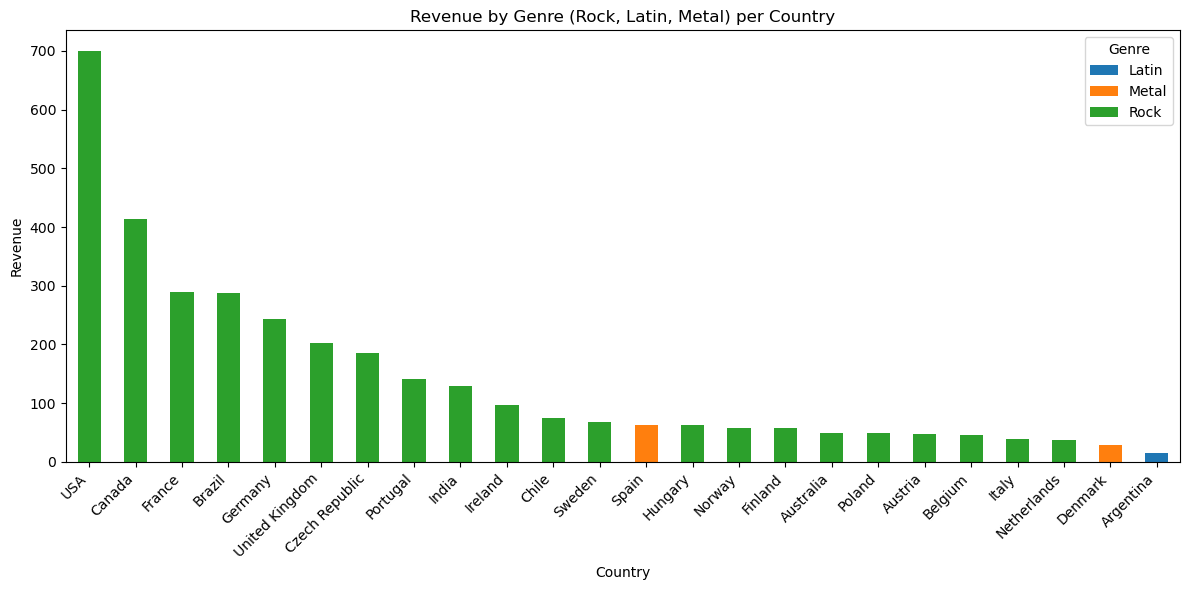

In [33]:
q="""SELECT
    i.billing_country AS country,
    g.name            AS genre,
    ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
FROM invoice_line il
JOIN invoice i ON i.invoice_id = il.invoice_id
JOIN track   t ON t.track_id   = il.track_id
JOIN genre   g ON g.genre_id   = t.genre_id
WHERE g.name IN ('Rock', 'Latin', 'Metal')
GROUP BY 1
ORDER BY i.billing_country, g.name;
"""
df=sql_query(q)
pivot = (df.pivot(index="country", columns="genre", values="revenue")
           .fillna(0))
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]  # biggest countries first

pivot.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.title("Revenue by Genre (Rock, Latin, Metal) per Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Genre")
plt.tight_layout()
plt.show()